internal nodeとexternal nodeでの変異獲得イベントの数のカウント
outgroup (SeCoV) baseで作成した系統樹で実施。

In [3]:
import pandas as pd

# 1. データの読み込み
df = pd.read_csv('/Users/izumikida/FCoV-evolution/Fig3_FCoV_tree_with_key_mutations/treetime/output/reg4/branch_mutations.txt', sep='\t')
df

,node,state1,pos,state2
0,NODE_0000001,S,51,A
1,NODE_0000001,Y,80,N
2,NODE_0000001,M,110,T
3,NODE_0000001,H,223,R
4,fecv_NARC4,S,69,A
...,...,...,...,...
841,NODE_0000112,S,136,G
842,NODE_0000113,R,70,L
843,FJ917523.1,S,194,P
844,FJ917523.1,L,227,F


In [9]:
target_pos = [48, 66, 68, 70, 71, 84]

# filtering
target_summary = df[df['pos'].isin(target_pos)].copy()

# set the pos same as the alignment
pos_map = {48: 791, 66: 809, 68: 811, 70: 813, 71: 814, 84: 826}
target_summary['pos'] = target_summary['pos'].map(pos_map)

# result
target_summary = target_summary.sort_values('pos')

target_summary.to_csv('reg4_branch_mutation_summary.tsv', sep='\t', index=False)

target_summary

,node,state1,pos,state2
642,NODE_0000092,A,791,V
135,FJ938058.1,A,791,V
600,NODE_0000088,A,791,V
518,c112,A,791,V
300,NODE_0000038,A,791,V
...,...,...,...,...
58,LC852817.1,T,826,I
510,LC880185.1,T,826,S
177,r1,T,826,I
373,NODE_0000052,T,826,I


In [11]:
df2 = pd.read_csv('/Users/izumikida/FCoV-evolution/Fig3_FCoV_tree_with_key_mutations/treetime/output/reg5/branch_mutations.txt', sep='\t')
df2

,node,state1,pos,state2
0,NODE_0000002,E,53,D
1,NODE_0000003,V,4,L
2,NODE_0000003,F,12,L
3,NODE_0000003,D,19,S
4,NODE_0000003,I,35,V
...,...,...,...,...
359,KX722529.1,R,24,K
360,NODE_0000112,V,35,I
361,fecv47,V,110,I
362,NODE_0000115,R,24,K


In [12]:
target_pos2 = [85, 101, 103]

# filtering
target_summary2 = df2[df2['pos'].isin(target_pos2)].copy()

# set the pos same as the alignment
pos_map2 = {85: 1056, 101: 1072, 103: 1074}
target_summary2['pos'] = target_summary2['pos'].map(pos_map2)

# result
target_summary2 = target_summary2.sort_values('pos')

target_summary2.to_csv('reg5_branch_mutation_summary.tsv', sep='\t', index=False)

target_summary2

,node,state1,pos,state2
12,NODE_0000005,D,1056,A
226,h7,G,1056,A
236,v5,G,1056,N
247,r1,G,1056,S
250,NODE_0000078,G,1056,D
258,MW308128.1,D,1056,G
278,NODE_0000084,G,1056,H
279,FJ917524.1,H,1056,A
285,FJ917523.1,H,1056,G
299,NODE_0000096,D,1056,G


In [15]:
df3 = pd.read_csv('/Users/izumikida/FCoV-evolution/Fig3_FCoV_tree_with_key_mutations/treetime/output/reg6/branch_mutations.txt', sep='\t')
df3

,node,state1,pos,state2
0,NODE_0000001,T,40,I
1,NODE_0000001,E,42,D
2,NODE_0000001,V,78,A
3,NODE_0000001,Y,192,D
4,NODE_0000001,N,215,G
...,...,...,...,...
812,fecv40,E,321,A
813,fecv43,A,122,S
814,fecv43,H,208,Y
815,fecv43,G,215,D


In [16]:
target_pos3 = [36, 40, 42, 67, 119, 277, 282]

# filtering
target_summary3 = df3[df3['pos'].isin(target_pos3)].copy()

# set the pos same as the alignment
pos_map3 = {36: 1129, 40: 1133, 42: 1135, 67: 1160, 119: 1212, 277: 1363, 282: 1368}
target_summary3['pos'] = target_summary3['pos'].map(pos_map3)

# result
target_summary3 = target_summary3.sort_values('pos')

target_summary3.to_csv('reg6_branch_mutation_summary.tsv', sep='\t', index=False)

target_summary3

,node,state1,pos,state2
513,v5,A,1129,S
40,NODE_0000006,A,1129,S
228,NODE_0000036,A,1129,S
665,MT444152.1,A,1129,S
0,NODE_0000001,T,1133,I
...,...,...,...,...
412,PP901878.1,P,1368,T
424,MW030108.1,P,1368,H
603,KX722530.1,P,1368,S
160,FJ938058.1,P,1368,S


In [ ]:
import pandas as pd
# combine mutation summary
files = {
    'reg4': 'reg4_branch_mutation_summary.tsv',
    'reg5': 'reg5_branch_mutation_summary.tsv',
    'reg6': 'reg6_branch_mutation_summary.tsv',

}

dfs = []
for nrr_id, file in files.items():
    df = pd.read_csv(file, sep='\t')
    df['nrr_id'] = nrr_id  # どのNRR由来かを示す列を追加
    dfs.append(df)

combined_df = pd.concat(dfs, ignore_index=True)

print(combined_df.head())

combined_df.to_csv('combine_NRR_branch_mutation_summary.tsv', sep='\t', index=False)

           node state1  pos state2 nrr_id
0  NODE_0000092      A  791      V   reg4
1    FJ938058.1      A  791      V   reg4
2  NODE_0000088      A  791      V   reg4
3          c112      A  791      V   reg4
4  NODE_0000038      A  791      V   reg4


In [18]:
branch_mut = pd.read_csv('/Users/izumikida/FCoV-evolution/Fig3_FCoV_tree_with_key_mutations/treetime/combine_NRR_branch_mutation_summary.tsv', sep='\t')
branch_mut


,node,state1,pos,state2,nrr_id
0,NODE_0000092,A,791,V,reg4
1,FJ938058.1,A,791,V,reg4
2,NODE_0000088,A,791,V,reg4
3,c112,A,791,V,reg4
4,NODE_0000038,A,791,V,reg4
...,...,...,...,...,...
243,PP901878.1,P,1368,T,reg6
244,MW030108.1,P,1368,H,reg6
245,KX722530.1,P,1368,S,reg6
246,FJ938058.1,P,1368,S,reg6


変異した後にfecv_consensusと一致する配列に戻る変異を獲得したもの

In [ ]:
from Bio import SeqIO
import pandas as pd

fasta_path = '/Users/izumikida/FCoV-evolution/Fig2_FIPV_vs_FECV_Fishers_exact_test/Spike/fecv_consensus.fas'

record = SeqIO.read(fasta_path, "fasta")

data = {
    'pos': range(1, len(record.seq) + 1),  
    'state2': list(record.seq)            
}

df_consensus = pd.DataFrame(data)
df_consensus

,pos,state2
0,1,M
1,2,I
2,3,V
3,4,L
4,5,L
...,...,...
1487,1488,V
1488,1489,H
1489,1490,I
1490,1491,H


Extract mutations substitute to FECV consensus aa

In [ ]:
import pandas as pd

df_consensus = df_consensus.rename(columns={'state2': 'consensus_state'})

merged_df = pd.merge(branch_mut, df_consensus, on='pos', how='inner')

# compare aa with consensus
match_df = merged_df[merged_df['state2'] == merged_df['consensus_state']]

print(match_df)

             node state1   pos state2 nrr_id consensus_state
5    NODE_0000095      V   791      A   reg4               A
23   NODE_0000002      G   809      S   reg4               S
102  NODE_0000078      G  1056      D   reg5               D
147            h7      L  1072      M   reg5               M
149  NODE_0000078      L  1072      M   reg5               M
158  NODE_0000001      T  1133      I   reg6               I
198  NODE_0000001      E  1135      D   reg6               D
228  NODE_0000001      H  1363      P   reg6               P
232  NODE_0000001      S  1368      P   reg6               P


In [21]:
# exclude substitution same as FECV consensus
filtered_branch_mut = branch_mut.drop(index=match_df.index)

# list of substitutions related with FIPV
filtered_branch_mut

,node,state1,pos,state2,nrr_id
0,NODE_0000092,A,791,V,reg4
1,FJ938058.1,A,791,V,reg4
2,NODE_0000088,A,791,V,reg4
3,c112,A,791,V,reg4
4,NODE_0000038,A,791,V,reg4
...,...,...,...,...,...
243,PP901878.1,P,1368,T,reg6
244,MW030108.1,P,1368,H,reg6
245,KX722530.1,P,1368,S,reg6
246,FJ938058.1,P,1368,S,reg6


count internal/external mutation at each position

In [23]:
# Classify nodes into internal and external
is_internal = filtered_branch_mut['node'].str.startswith('NODE_')

# Count mutations per pos for internal and external nodes
mutation_counts = (
    filtered_branch_mut.groupby(['pos', is_internal.rename('is_internal')])
    .size()
    .unstack(fill_value=0)
    .rename(columns={True: 'internal_count', False: 'external_count'})
    .reset_index()
)

mutation_counts.to_csv('int_ext_counts_by_pos.tsv', sep='\t', index=False)

# Display result
mutation_counts

is_internal,pos,external_count,internal_count
0,791,9,7
1,809,25,7
2,811,10,2
3,813,3,1
4,814,22,3
5,826,6,1
6,1056,19,6
7,1072,18,7
8,1074,2,1
9,1129,2,2


create graph

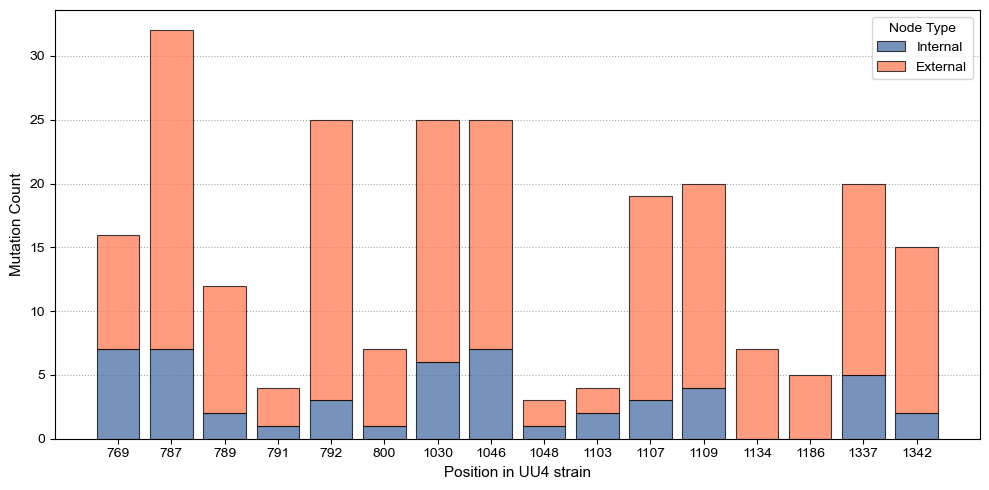

In [26]:
import matplotlib.pyplot as plt
import pandas as pd

# Set global font to Arial
plt.rcParams["font.sans-serif"] = "Arial"
plt.rcParams["font.family"] = "sans-serif"

# Load data
df = pd.read_csv("int_ext_counts_by_pos.tsv", sep="\t")

# Map position in this study to UU4 strain position
uu4_map = {
    791: 769,
    809: 787,
    811: 789,
    813: 791,
    814: 792,
    826: 800,
    1056: 1030,
    1072: 1046,
    1074: 1048,
    1129: 1103,
    1133: 1107,
    1135: 1109,
    1160: 1134,
    1212: 1186,
    1363: 1337,
    1368: 1342,
}

# Convert 'pos' column to UU4 positions and sort by ascending order
df["pos_uu4"] = df["pos"].map(uu4_map)
df = df.sort_values("pos_uu4").reset_index(drop=True)

x_labels = df["pos_uu4"].astype(str)

fig, ax = plt.subplots(figsize=(10, 5))

# Define colors
color_internal = "#4a6fa5"  # Slate blue
color_external = "#ff7b54"  # Coral

# Plot stacked bar chart
ax.bar(
    x_labels,
    df["internal_count"],
    label="Internal",
    color=color_internal,
    alpha=0.75,
    edgecolor="black",
    linewidth=0.8,
)
ax.bar(
    x_labels,
    df["external_count"],
    bottom=df["internal_count"],
    label="External",
    color=color_external,
    alpha=0.75,
    edgecolor="black",
    linewidth=0.8,
)

# Set labels and grid lines
ax.set_xlabel("Position in UU4 strain", fontsize=11)
ax.set_ylabel("Mutation Count", fontsize=11)
ax.grid(axis="y", linestyle=":", color="gray", alpha=0.7)
ax.set_axisbelow(True)
ax.legend(title="Node Type", frameon=True)

plt.tight_layout()
plt.savefig("int_ext_count_stacked_bar_uu4pos.svg", format="svg")  # Save as SVG
plt.show()